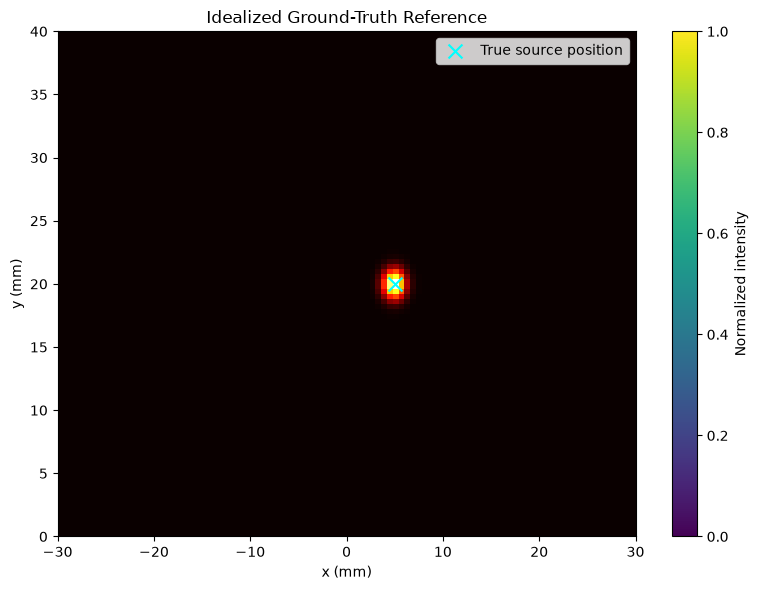

{
    "day": 27,
    "reference_type": "idealized Gaussian point source",
    "image_shape": [
        100,
        100
    ],
    "source_position_mm": [
        5.0,
        20.0
    ],
    "gaussian_sigma_mm": 0.8,
    "peak_position_mm": [
        5.15151515151515,
        20.2020202020202
    ],
    "localization_error_mm": 0.2525252525252498,
    "maximum_intensity": 1.0,
    "minimum_intensity": 0.0
}

Day 27 completed!
Image saved to: ..\outputs\day27_ground_truth.png
Results saved to: ..\outputs\day27_ground_truth_results.json


In [1]:

import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Output directory
output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Simulation parameters (same as Days 24-26)
image_size = 100

x_grid = np.linspace(-0.03, 0.03, image_size)
y_grid = np.linspace(0.0, 0.04, image_size)

X, Y = np.meshgrid(x_grid, y_grid)

# Known source position
source_x = 0.005  # 5 mm
source_y = 0.020  # 20 mm

# Idealized point-source reference
# Gaussian width: 0.8 mm
sigma = 0.8e-3

ground_truth = np.exp(
    -(
        (X - source_x)**2 +
        (Y - source_y)**2
    ) / (2 * sigma**2)
)

# Normalize reference image
ground_truth /= np.max(ground_truth)

# Locate maximum intensity
peak_row, peak_col = np.unravel_index(
    np.argmax(ground_truth),
    ground_truth.shape
)

estimated_x = float(X[peak_row, peak_col])
estimated_y = float(Y[peak_row, peak_col])

localization_error_mm = float(
    np.sqrt(
        (estimated_x - source_x)**2 +
        (estimated_y - source_y)**2
    ) * 1000
)

# Plot ground-truth reference
plt.figure(figsize=(8, 6))

plt.imshow(
    ground_truth,
    extent=[
        x_grid[0] * 1000,
        x_grid[-1] * 1000,
        y_grid[0] * 1000,
        y_grid[-1] * 1000
    ],
    origin="lower",
    aspect="auto",
    cmap="hot",
    vmin=0,
    vmax=1
)

plt.scatter(
    [source_x * 1000],
    [source_y * 1000],
    marker="x",
    s=100,
    color="cyan",
    label="True source position"
)

plt.xlabel("x (mm)")
plt.ylabel("y (mm)")
plt.title("Idealized Ground-Truth Reference")
plt.colorbar(label="Normalized intensity")
plt.legend()
plt.tight_layout()

plt.savefig(
    output_dir / "day27_ground_truth.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save numerical results
results = {
    "day": 27,
    "reference_type": "idealized Gaussian point source",
    "image_shape": list(ground_truth.shape),
    "source_position_mm": [
        source_x * 1000,
        source_y * 1000
    ],
    "gaussian_sigma_mm": sigma * 1000,
    "peak_position_mm": [
        estimated_x * 1000,
        estimated_y * 1000
    ],
    "localization_error_mm": localization_error_mm,
    "maximum_intensity": float(np.max(ground_truth)),
    "minimum_intensity": float(np.min(ground_truth))
}

with open(
    output_dir / "day27_ground_truth_results.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(results, f, indent=4)

print(json.dumps(results, indent=4))
print("\nDay 27 completed!")
print(f"Image saved to: {output_dir / 'day27_ground_truth.png'}")
print(f"Results saved to: {output_dir / 'day27_ground_truth_results.json'}")
